# Image to Poem 🖼️ → 📝
### A student machine-learning project: photo → caption → mood → 8-line poem

Upload a photo. The system
1. writes a **caption** of what is in the picture,
2. predicts the **mood** (*happy / sad / calm / energetic*) with a classifier **I trained**,
3. writes an 8-line rhyming **poem** with a small language model that **I fine-tuned** on my own image → poem dataset.

Everything runs on a laptop CPU/Apple-Silicon, offline after the first model download.

```
image ──┬──► BLIP captioner (pretrained, frozen) ────────────────────────────► caption ─┐
        │                                                                               ├──► Qwen2.5-0.5B + my LoRA ──► 8-line poem
        └──► CLIP ViT-B/32 (frozen) ─► 512-d ─► Scaler ─► PCA ─► my classifier ─► mood ─┘
             (feature extractor)                         (trained from scratch by me)
```

### What is pretrained and what did I train? (honest table)

| Part | Model | Pretrained? | What I did |
|---|---|---|---|
| Captioner | BLIP base (Salesforce) | ✅ pretrained, **frozen** | used as-is |
| Image features | CLIP ViT-B/32 (OpenAI) | ✅ pretrained, **frozen** | used as a **feature extractor** (image → 512-d vector) |
| Mood classifier | Scaler + PCA + 5 scikit-learn models | ❌ | **trained from scratch** on my 251 labelled images, compared 5 models, picked the best by CV |
| Poem writer | Qwen2.5-0.5B-Instruct | ✅ pretrained base | **fine-tuned with LoRA** (supervised) on my own image → poem dataset |

### How to use this notebook
It runs top-to-bottom in a few minutes by **loading saved results**. The slow steps (downloading images,
CLIP features, building the poem dataset, LoRA training, evaluation) are real code cells, switched off with flags
below. Set a flag to `True` to redo that step with the code in `src/`.

In [1]:
# --- setup: run from the project root, offline, quiet ---
import os, sys, time, json, warnings
from pathlib import Path

if Path.cwd().name == "notebook":
    os.chdir(Path.cwd().parent)
ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["HF_HUB_OFFLINE"] = "1"            # models come from ~/.cache/huggingface
os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")
NOTEBOOK_START = time.perf_counter()
print("project root:", ROOT)

project root: ImageToPoem


In [2]:
# --- flags: True = redo the heavy step (slow), False = load saved results (fast) ---
RETRAIN_MOOD  = False   # download images + CLIP features + train_mood   (~5-10 min)
REBUILD_POEMS = False   # caption + 8 candidate poems per image + scoring  (~30-60 min)
RETRAIN_POET  = False   # LoRA fine-tuning of Qwen2.5-0.5B                 (~15-30 min)
REEVAL_POET   = False   # base vs fine-tuned on test images                (~10-20 min)

In [3]:
# --- imports from my project code (src/) + one plot style for the whole notebook ---
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

from src.utils import (DATA_DIR, MODELS_DIR, REPORTS_DIR, FEATURES_FILE, PCA_FILE,
                       MODEL_FILE, MOODS, timer)
from src.features import list_dataset
from src.train_mood import MODELS, make_pipeline, SEED, PCA_VARIANCE
from src.evaluate import scores
from src.poem_metrics import score_poem, poem_lines

# src/evaluate.py switches matplotlib to the file-only "Agg" backend -> switch back to inline
%matplotlib inline
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "font.size": 11, "figure.dpi": 110,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})
MOOD_COLORS = {"happy": "#e8a33d", "sad": "#4a6fa5", "calm": "#2f8f83", "energetic": "#d0503c"}
BASE_C, FT_C = "#9aa5b1", "#3b5bdb"          # base model vs fine-tuned model
POEMS_DIR = DATA_DIR / "poems"
LORA_DIR = MODELS_DIR / "poet_lora"


def load_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]


def missing(*paths):
    # print a friendly note if saved results are missing; True = skip this cell
    gone = [str(Path(p).relative_to(ROOT)) for p in paths if not Path(p).exists()]
    if gone:
        print("⚠️  not found yet:", ", ".join(gone), "-> set the matching flag to True (or run the src script) first.")
    return bool(gone)


def inline_again():
    # some src modules switch matplotlib to Agg on import; call this after importing them
    get_ipython().run_line_magic("matplotlib", "inline")


print("moods:", MOODS)

moods: ['happy', 'sad', 'calm', 'energetic']


## 1 · Dataset

* **251 Creative-Commons photos** from [Openverse](https://openverse.org), searched with several queries per mood
  (e.g. *calm*: "calm lake", "misty forest", "zen garden").
* I then **cleaned the labels by hand** (deleted images that did not fit the mood). The folder name is the **label** →
  this is a **supervised** dataset: input = image, target = mood.
* 4 classes, roughly **balanced**, so plain accuracy is a fair metric (I also report macro F1).

In [4]:
if RETRAIN_MOOD:   # heavy: download images -> CLIP features -> train + save the mood model
    from src import build_dataset, features, train_mood
    sys.argv = ["build_dataset", "--per-mood", "60"]     # build_dataset uses argparse
    build_dataset.main()
    features.main()
    train_mood.main()
    inline_again()
else:
    print("RETRAIN_MOOD=False -> using saved models/features.npz, pca.joblib, mood_model.joblib")

RETRAIN_MOOD=False -> using saved models/features.npz, pca.joblib, mood_model.joblib


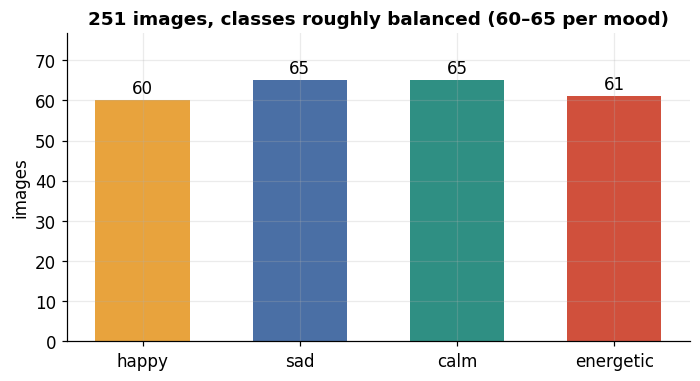

In [5]:
data = np.load(FEATURES_FILE)
X, y = data["X"], data["y"]
paths, labels = list_dataset()

counts = pd.Series(y).value_counts().reindex(MOODS)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(counts.index, counts.values, color=[MOOD_COLORS[m] for m in MOODS], width=0.6)
ax.bar_label(bars, padding=2)
ax.set_ylabel("images")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_title(f"{len(y)} images, classes roughly balanced ({counts.min()}–{counts.max()} per mood)")
plt.tight_layout(); plt.show()

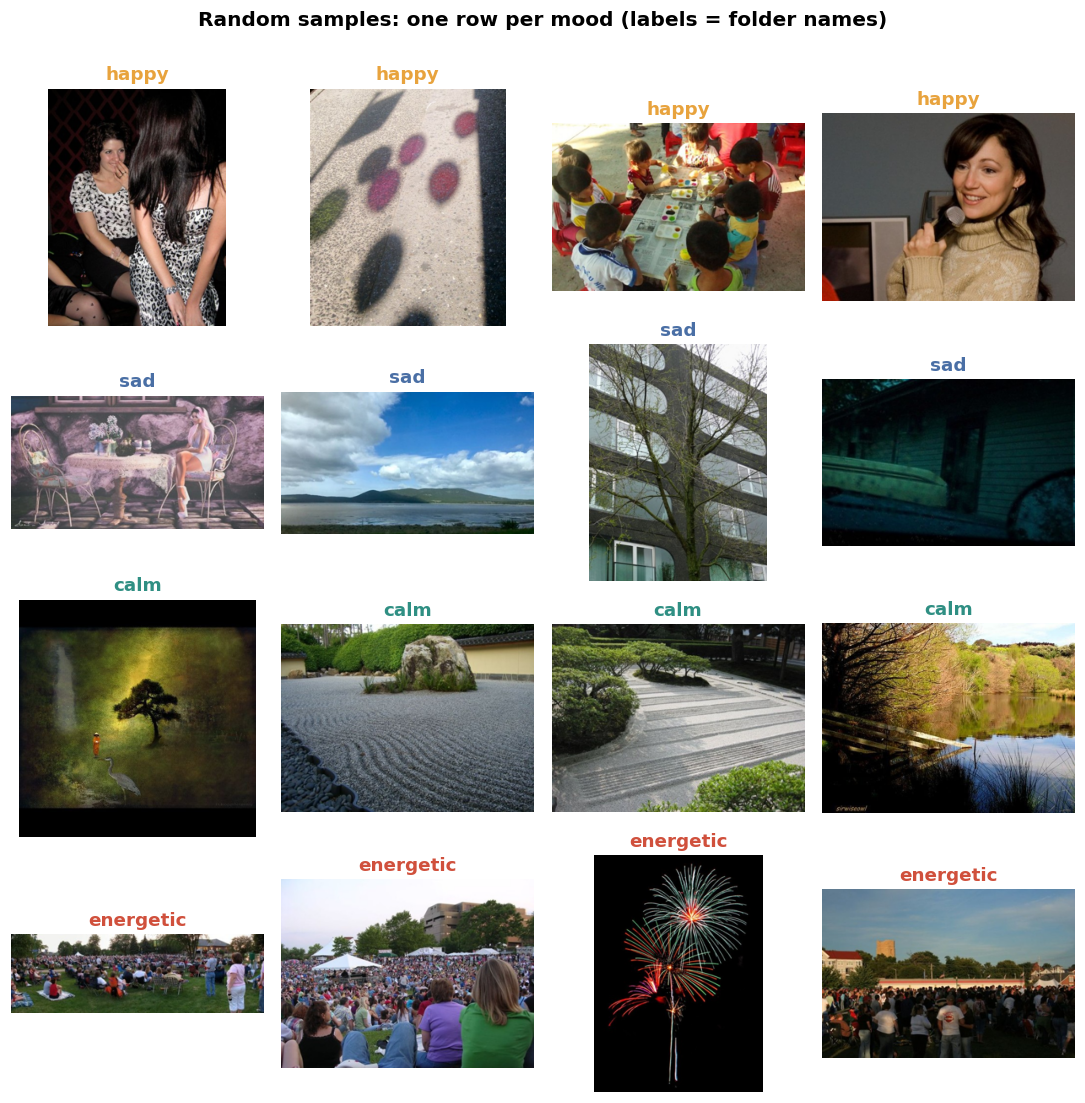

In [6]:
rng = np.random.default_rng(7)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for row, mood in zip(axes, MOODS):
    mood_paths = [p for p, l in zip(paths, labels) if l == mood]
    for ax, p in zip(row, rng.choice(mood_paths, 4, replace=False)):
        img = Image.open(p).convert("RGB")
        img.thumbnail((300, 300))
        ax.imshow(img)
        ax.set_title(mood, color=MOOD_COLORS[mood], fontweight="bold")
        ax.axis("off")
fig.suptitle("Random samples: one row per mood (labels = folder names)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

## 2 · Features: CLIP embeddings + PCA

* **Feature extraction**: every image goes through the frozen **CLIP ViT-B/32** image encoder → a vector of
  **512 numbers** (an *embedding*). Similar-looking / similar-meaning images get similar vectors.
  I **L2-normalise** each vector (length 1) so distances are fair.
* **Preprocessing**: `StandardScaler` → every feature gets mean 0, std 1.
* **Dimensionality reduction (PCA)**: 512 features but only ~200 training images → risk of **overfitting**.
  PCA keeps the directions with the most **variance**; I keep enough components for **90 %** of the variance.

In [7]:
print("X (CLIP embeddings):", X.shape, X.dtype, "   y:", y.shape)
print("vector lengths (should be 1.0 after L2-normalising):", np.linalg.norm(X, axis=1)[:5].round(3))

pca_pipe = joblib.load(PCA_FILE)            # saved StandardScaler + PCA (fit on all images)
print(pca_pipe)
saved_pca = pca_pipe.named_steps["pca"]
print(f"saved PCA: 512 -> {saved_pca.n_components_} components "
      f"({saved_pca.explained_variance_ratio_.sum():.1%} variance kept)")

X (CLIP embeddings): (251, 512) float32    y: (251,)
vector lengths (should be 1.0 after L2-normalising): [1. 1. 1. 1. 1.]
Pipeline(steps=[('scale', StandardScaler()),
                ('pca', PCA(n_components=0.9, random_state=42))])
saved PCA: 512 -> 113 components (90.2% variance kept)


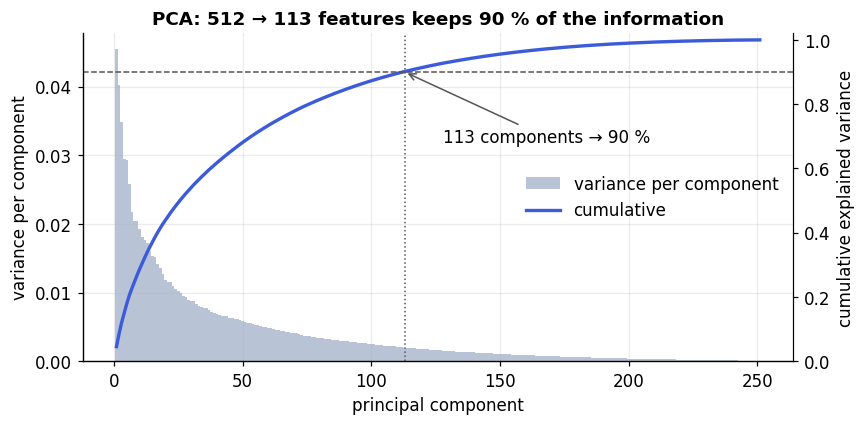

In [8]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

full = PCA().fit(StandardScaler().fit_transform(X))          # all components, to see the whole curve
ratio = full.explained_variance_ratio_
cum = np.cumsum(ratio)
n90 = int(np.searchsorted(cum, 0.90) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
k = np.arange(1, len(ratio) + 1)
ax.bar(k, ratio, color="#b8c4d6", width=1.0, label="variance per component")
ax2 = ax.twinx()
ax2.plot(k, cum, color=FT_C, lw=2.2, label="cumulative")
ax2.axhline(0.90, ls="--", color="#555", lw=1)
ax2.axvline(n90, ls=":", color="#555", lw=1)
ax2.annotate(f"{n90} components → 90 %", (n90, 0.90), xytext=(n90 + 15, 0.68),
             arrowprops=dict(arrowstyle="->", color="#555"))
ax2.set_ylim(0, 1.02); ax2.set_ylabel("cumulative explained variance"); ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_xlabel("principal component"); ax.set_ylabel("variance per component")
ax.set_title(f"PCA: 512 → {n90} features keeps 90 % of the information")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right", frameon=False)
plt.tight_layout(); plt.show()

## 3 · Supervised learning: mood classification

Same **Pipeline** for every model: `StandardScaler → PCA(90 %) → classifier`. Because scaler and PCA live *inside*
the pipeline, they are re-fit on each training fold → **no data leakage**.

| Model | Syllabus topic |
|---|---|
| **Logistic Regression** | linear classifier, softmax |
| **KNN** (k = 5, distance-weighted) | instance-based learning |
| **Decision Tree** (max depth 8) | tree / information gain |
| **Random Forest** (200 trees) | **ensemble** (bagging + majority vote) |
| **MLP** (1 hidden layer, 128 ReLU) | **neural network** |

**Evaluation**: stratified **80/20 train/test split**; on the training part **stratified 5-fold cross-validation**.
I choose the best model by **CV accuracy** (not by test accuracy, so the test set stays an honest final check).
This is cheap, so it runs **live** below.

In [9]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"train {len(y_tr)} images · test {len(y_te)} images · 5-fold CV on train\n")

rows, fitted = [], {}
for name, clf in MODELS.items():
    pipe = make_pipeline(clone(clf))
    t0 = time.perf_counter()
    cv_acc = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="accuracy")
    pipe.fit(X_tr, y_tr)
    secs = time.perf_counter() - t0
    s = scores(y_te, pipe.predict(X_te))
    fitted[name] = pipe
    rows.append({"model": name, "cv_acc_mean": cv_acc.mean(), "cv_acc_std": cv_acc.std(),
                 **{f"test_{k}": v for k, v in s.items()}, "seconds": secs})
    print(f"{name:20s} CV acc {cv_acc.mean():.3f} ± {cv_acc.std():.3f}   "
          f"test acc {s['accuracy']:.3f}   test F1 {s['f1']:.3f}   [{secs:.2f}s]")

results = pd.DataFrame(rows).sort_values("cv_acc_mean", ascending=False).reset_index(drop=True)
best_name = results.loc[0, "model"]
print(f"\nBest by CV: {best_name}   (all 5 models trained in {results.seconds.sum():.1f}s)")
display(results.round(3))

saved = pd.read_csv(REPORTS_DIR / "model_comparison.csv")
print("Saved run (reports/model_comparison.csv) for comparison — should match:")
display(saved.round(3))

train 200 images · test 51 images · 5-fold CV on train



Logistic Regression  CV acc 0.870 ± 0.046   test acc 0.863   test F1 0.860   [0.04s]
KNN                  CV acc 0.875 ± 0.052   test acc 0.843   test F1 0.838   [0.11s]


Decision Tree        CV acc 0.680 ± 0.033   test acc 0.706   test F1 0.704   [0.07s]


Random Forest        CV acc 0.835 ± 0.046   test acc 0.863   test F1 0.859   [1.20s]


MLP                  CV acc 0.835 ± 0.049   test acc 0.882   test F1 0.882   [0.40s]

Best by CV: KNN   (all 5 models trained in 1.8s)


,model,cv_acc_mean,cv_acc_std,test_accuracy,test_precision,test_recall,test_f1,seconds
0,KNN,0.875,0.052,0.843,0.842,0.840,0.838,0.112
1,Logistic Regression,0.870,0.046,0.863,0.866,0.861,0.860,0.045
2,Random Forest,0.835,0.046,0.863,0.876,0.859,0.859,1.195
3,MLP,0.835,0.049,0.882,0.901,0.880,0.882,0.405
4,Decision Tree,0.680,0.033,0.706,0.715,0.704,0.704,0.072


Saved run (reports/model_comparison.csv) for comparison — should match:


,model,cv_acc_mean,cv_acc_std,test_accuracy,test_precision,test_recall,test_f1
0,KNN,0.875,0.052,0.843,0.842,0.840,0.838
1,Logistic Regression,0.870,0.046,0.863,0.866,0.861,0.860
2,Random Forest,0.835,0.046,0.863,0.876,0.859,0.859
3,MLP,0.835,0.049,0.882,0.901,0.880,0.882
4,Decision Tree,0.680,0.033,0.706,0.715,0.704,0.704


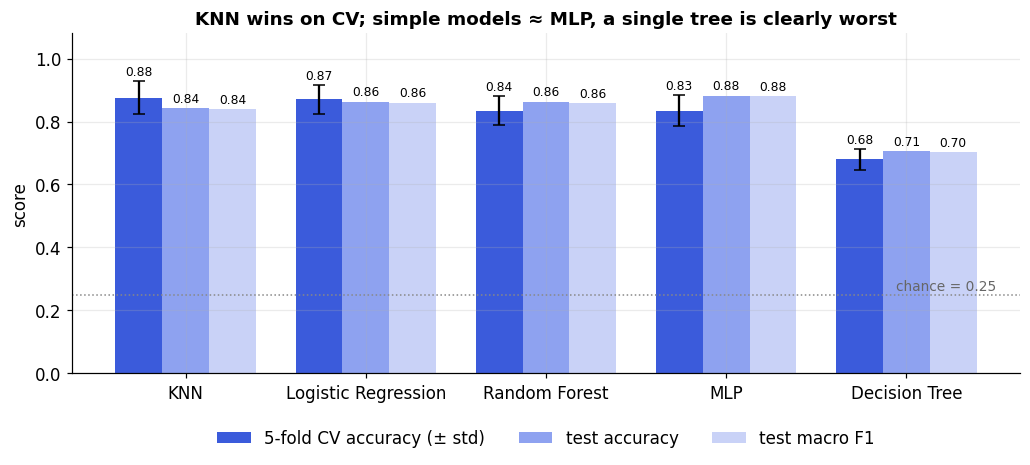

In [10]:
order = results["model"].tolist()
x = np.arange(len(order))
w = 0.26
fig, ax = plt.subplots(figsize=(9.5, 4.4))
b1 = ax.bar(x - w, results["cv_acc_mean"], w, yerr=results["cv_acc_std"], capsize=4,
            color="#3b5bdb", label="5-fold CV accuracy (± std)")
b2 = ax.bar(x, results["test_accuracy"], w, color="#8ea2f0", label="test accuracy")
b3 = ax.bar(x + w, results["test_f1"], w, color="#c9d2f7", label="test macro F1")
for b in (b1, b2, b3):
    ax.bar_label(b, fmt="%.2f", fontsize=8, padding=2)
ax.axhline(0.25, ls=":", color="#888", lw=1)
ax.text(len(order) - 0.5, 0.265, "chance = 0.25", ha="right", fontsize=9, color="#666")
ax.set_xticks(x, order)
ax.set_ylim(0, 1.08); ax.set_ylabel("score")
ax.set_title(f"{best_name} wins on CV; simple models ≈ MLP, a single tree is clearly worst")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

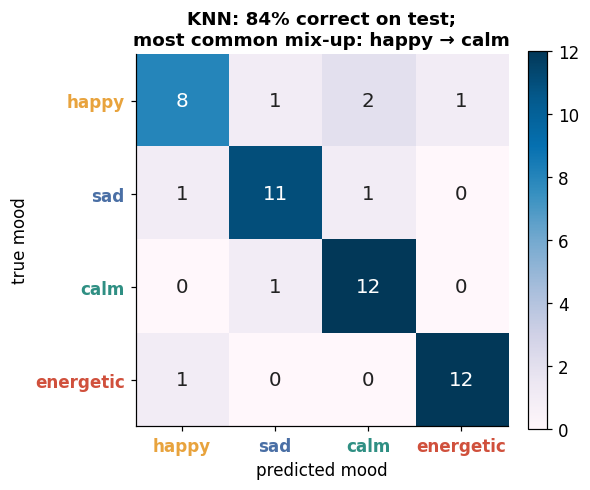

Classification report — KNN on the held-out test set

              precision    recall  f1-score   support

       happy       0.80      0.67      0.73        12
         sad       0.85      0.85      0.85        13
        calm       0.80      0.92      0.86        13
   energetic       0.92      0.92      0.92        13

    accuracy                           0.84        51
   macro avg       0.84      0.84      0.84        51
weighted avg       0.84      0.84      0.84        51



In [11]:
from sklearn.metrics import confusion_matrix, classification_report

best = fitted[best_name]
y_pred = best.predict(X_te)
cm = confusion_matrix(y_te, y_pred, labels=MOODS)

fig, ax = plt.subplots(figsize=(5.4, 4.8))
im = ax.imshow(cm, cmap="PuBu")
for i in range(len(MOODS)):
    for j in range(len(MOODS)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                color="white" if cm[i, j] > cm.max() / 2 else "#222")
ax.set_xticks(range(4), MOODS); ax.set_yticks(range(4), MOODS)
for t in ax.get_xticklabels() + ax.get_yticklabels():
    t.set_color(MOOD_COLORS[t.get_text()]); t.set_fontweight("bold")
ax.set_xlabel("predicted mood"); ax.set_ylabel("true mood"); ax.grid(False)
acc = np.trace(cm) / cm.sum()
off = cm - np.diag(np.diag(cm))
i, j = np.unravel_index(off.argmax(), off.shape)
ax.set_title(f"{best_name}: {acc:.0%} correct on test;\nmost common mix-up: {MOODS[i]} → {MOODS[j]}")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

print(f"Classification report — {best_name} on the held-out test set\n")
print(classification_report(y_te, y_pred, labels=MOODS, zero_division=0))

In [12]:
# the model actually used by the app (refit on ALL images after choosing it by CV)
saved_model = joblib.load(MODEL_FILE)
print("models/mood_model.joblib ->", saved_model["name"], "|", saved_model["model"])

models/mood_model.joblib -> KNN | KNeighborsClassifier(weights='distance')


## 4 · Unsupervised learning: do the moods form natural clusters?

Forget the labels for a moment. **K-Means** groups the CLIP vectors into *k* clusters.
* **Elbow method**: plot **inertia** (within-cluster sum of squares) vs *k*, look for the bend.
* **Silhouette score** (−1 … 1): how well separated the clusters are.
* **ARI** (adjusted Rand index): how well the k = 4 clusters match the real moods (0 = random, 1 = perfect).

Then two 2-D pictures of the 512-D data: **PCA** (linear projection) and **t-SNE** (non-linear, keeps neighbours close).

K-Means for k=2..8 in 0.7s   |   k=4: silhouette 0.047, ARI vs true moods 0.281


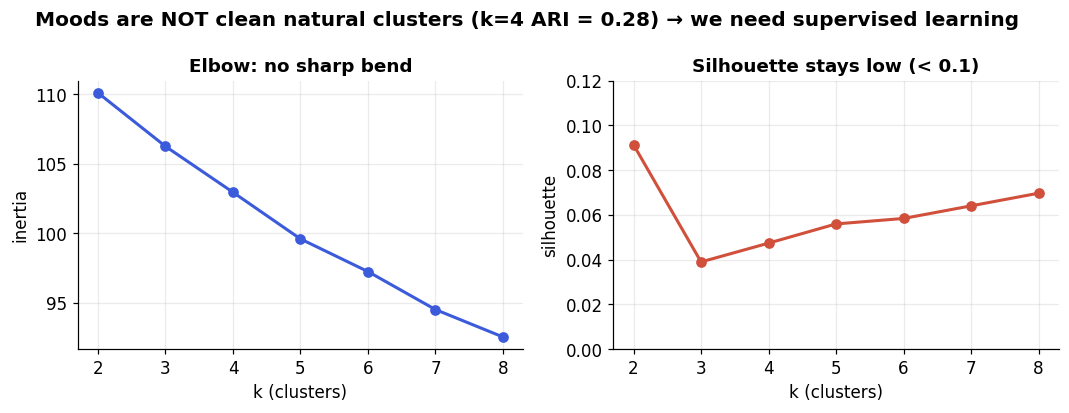

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

ks = list(range(2, 9))
inertia, sil = [], []
t0 = time.perf_counter()
for k in ks:
    km = KMeans(k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))
km4 = KMeans(4, n_init=10, random_state=42).fit(X)
ari = adjusted_rand_score(y, km4.labels_)
print(f"K-Means for k=2..8 in {time.perf_counter() - t0:.1f}s   |   k=4: silhouette "
      f"{sil[ks.index(4)]:.3f}, ARI vs true moods {ari:.3f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.plot(ks, inertia, "o-", color=FT_C, lw=2)
a1.set_xlabel("k (clusters)"); a1.set_ylabel("inertia"); a1.set_title("Elbow: no sharp bend")
a2.plot(ks, sil, "o-", color="#d0503c", lw=2)
a2.set_xlabel("k (clusters)"); a2.set_ylabel("silhouette"); a2.set_title("Silhouette stays low (< 0.1)")
a2.set_ylim(0, max(0.12, max(sil) * 1.3))
fig.suptitle(f"Moods are NOT clean natural clusters (k=4 ARI = {ari:.2f}) → we need supervised learning",
             fontweight="bold")
plt.tight_layout(); plt.show()

t-SNE on 251 points: 0.6s


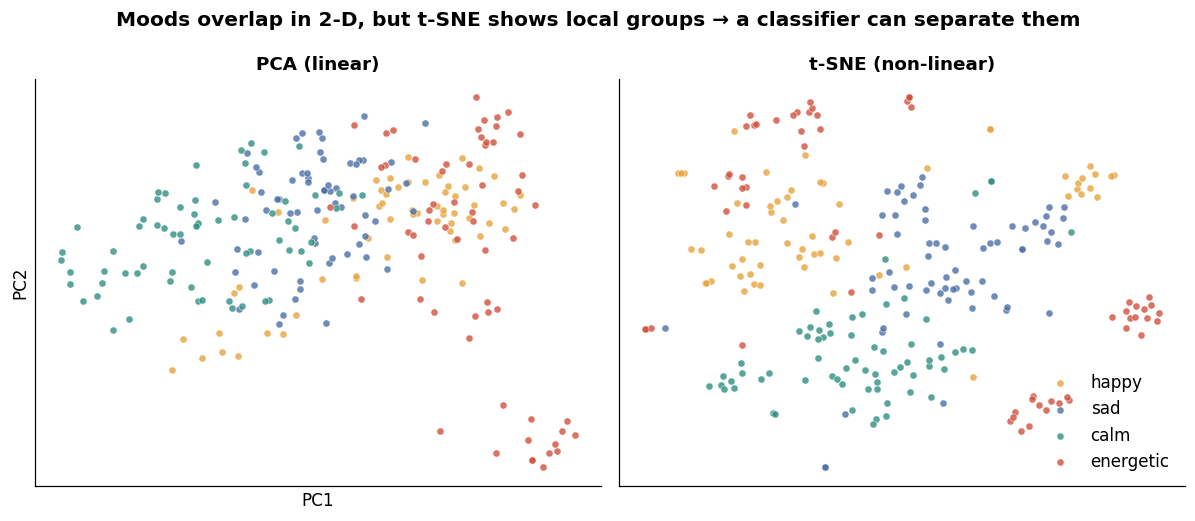

In [14]:
from sklearn.manifold import TSNE

Xs = StandardScaler().fit_transform(X)
X_pca2 = PCA(n_components=2, random_state=42).fit_transform(Xs)
t0 = time.perf_counter()
X_50 = PCA(n_components=50, random_state=42).fit_transform(Xs)      # usual trick: PCA first, then t-SNE
X_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(X_50)
print(f"t-SNE on {len(X)} points: {time.perf_counter() - t0:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, Z, name in ((axes[0], X_pca2, "PCA (linear)"), (axes[1], X_tsne, "t-SNE (non-linear)")):
    for mood in MOODS:
        m = y == mood
        ax.scatter(Z[m, 0], Z[m, 1], s=22, alpha=0.8, color=MOOD_COLORS[mood],
                   edgecolor="white", linewidth=0.4, label=mood)
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[1].legend(frameon=False, loc="best")
fig.suptitle("Moods overlap in 2-D, but t-SNE shows local groups → a classifier can separate them",
             fontweight="bold")
plt.tight_layout(); plt.show()

## 5 · Building my image → poem dataset

To fine-tune the poem model I need **pairs**: *(caption + mood) → good poem*. Nobody has that dataset for my images,
so I built it myself (`src/poem_data.py`):

1. **Split images first** 80 / 10 / 10 (train / val / test, stratified by mood) → no image appears in two splits (**no leakage**).
2. For each image: **BLIP caption**; the mood is my folder **label**.
3. A **"teacher" prompt**: the *same* base model (Qwen2.5-0.5B-Instruct) gets a long, strict prompt
   (rules: exactly 8 lines, AABB rhyme, simple words + one worked example) and samples **8 candidate poems**.
4. Every candidate is scored by my **quality scorer** (`src/poem_metrics.py`):
   `total = 0.4·rhyme + 0.3·keyword + 0.3·mood − penalties` (repeated lines, too-long lines, "here's a poem…").
5. **Keep the best** (2 per train image, 1 per val image, only if score ≥ 0.45 and exactly 8 lines).
   Test images get **no poems**: the model must write them during evaluation.

The training input is only the **short** prompt. So the model learns to write like the long-prompt teacher *without*
the long prompt. This is called **rejection-sampling fine-tuning** / **prompt distillation**.

> **Honest note:** the target poems are *not* written by humans. They are generated by the base model with a strict
> prompt and then **filtered by my scorer**. So the fine-tuned model can only become as good as the best of its own
> samples — what it learns is *consistency* (format, rhyme, staying on topic), not new poetic talent.

In [15]:
if REBUILD_POEMS:   # heavy: BLIP caption + 8 sampled poems per image + scoring
    from src import poem_data
    poem_data.main()
    inline_again()
else:
    print("REBUILD_POEMS=False -> using saved data/poems/{train,val,test}.jsonl + scores.json")

from src.poem_data import TEACHER_SYSTEM, N_CANDIDATES, KEEP_PER_IMAGE, MIN_SCORE
from src.poem import PROMPT
print(f"\nN_CANDIDATES={N_CANDIDATES}  KEEP_PER_IMAGE={KEEP_PER_IMAGE}  MIN_SCORE={MIN_SCORE}")
print("\n--- teacher system prompt (used only to BUILD the data) ---\n" + TEACHER_SYSTEM)
print("\n--- short student prompt (used for training + in the app) ---\n" + PROMPT)

REBUILD_POEMS=False -> using saved data/poems/{train,val,test}.jsonl + scores.json

N_CANDIDATES=8  KEEP_PER_IMAGE=2  MIN_SCORE=0.45

--- teacher system prompt (used only to BUILD the data) ---
You are a careful poet. Rules:
- Exactly 8 lines: two verses of 4 lines, blank line between them.
- Rhyme scheme AABB in each verse (line 1 rhymes with 2, line 3 with 4).
- Simple words, vivid pictures, max 9 words per line.
- Talk about the things in the scene. Match the mood.
- Output only the poem. No title, no notes.

--- short student prompt (used for training + in the app) ---
Write a short 8-line poem about: {caption}. Mood: {mood}. Use vivid imagery, simple words, and a gentle rhyme.


In [16]:
POEM_FILES = [POEMS_DIR / f"{s}.jsonl" for s in ("train", "val", "test")]
if not missing(*POEM_FILES):
    splits = {s: load_jsonl(POEMS_DIR / f"{s}.jsonl") for s in ("train", "val", "test")}
    table = pd.DataFrame({
        "images": {s: len({r["image"] for r in rows}) for s, rows in splits.items()},
        "poem pairs": {s: sum("poem" in r for r in rows) for s, rows in splits.items()},
    })
    table["used for"] = ["LoRA training", "validation loss", "final evaluation (no poems: model writes them)"]
    display(table)
    by_mood = pd.DataFrame({s: pd.Series([r["mood"] for r in rows]).value_counts()
                            for s, rows in splits.items()}).reindex(MOODS).fillna(0).astype(int)
    print("rows per mood:"); display(by_mood)

,images,poem pairs,used for
train,163,270,LoRA training
val,19,19,validation loss
test,26,0,final evaluation (no poems: model writes them)


rows per mood:


,train,val,test
happy,67,4,6
sad,72,5,7
calm,80,7,6
energetic,51,3,7


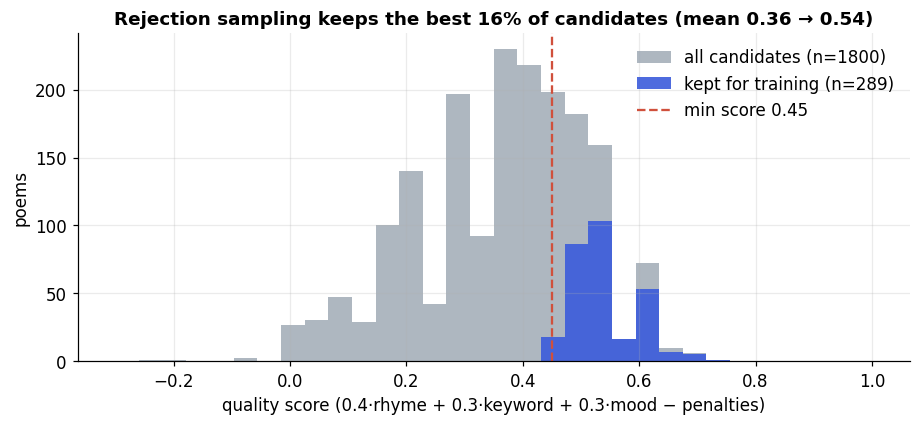

In [17]:
if not missing(POEMS_DIR / "scores.json"):
    sc = json.load(open(POEMS_DIR / "scores.json"))
    cand, kept = np.array(sc["candidate_scores"]), np.array(sc["kept_scores"])
    bins = np.linspace(min(cand.min(), -0.3), 1.0, 33)
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.hist(cand, bins=bins, color=BASE_C, alpha=0.8, label=f"all candidates (n={len(cand)})")
    ax.hist(kept, bins=bins, color=FT_C, alpha=0.9, label=f"kept for training (n={len(kept)})")
    ax.axvline(MIN_SCORE, ls="--", color="#d0503c", lw=1.5, label=f"min score {MIN_SCORE}")
    ax.set_xlabel("quality score (0.4·rhyme + 0.3·keyword + 0.3·mood − penalties)")
    ax.set_ylabel("poems")
    ax.set_title(f"Rejection sampling keeps the best {len(kept) / len(cand):.0%} of candidates "
                 f"(mean {cand.mean():.2f} → {kept.mean():.2f})")
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

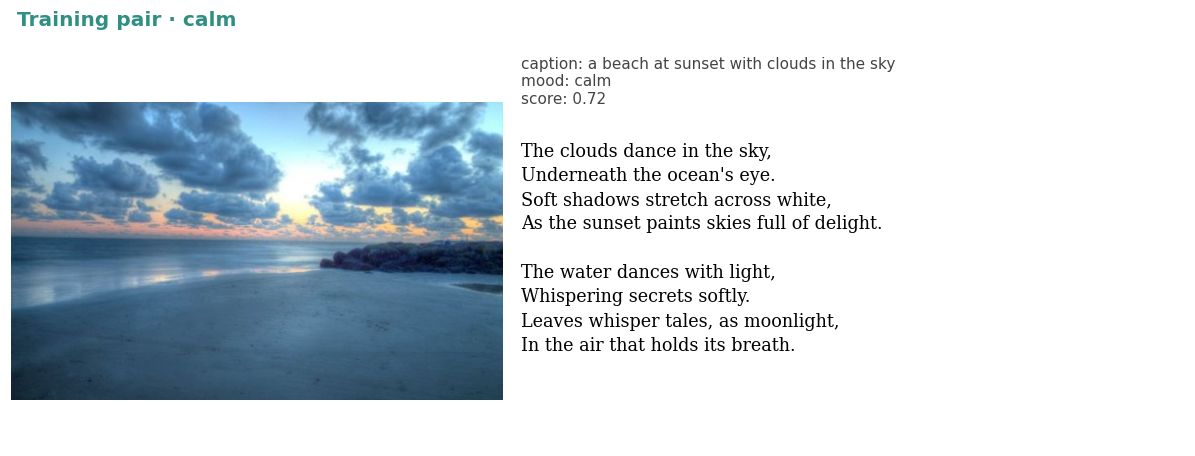

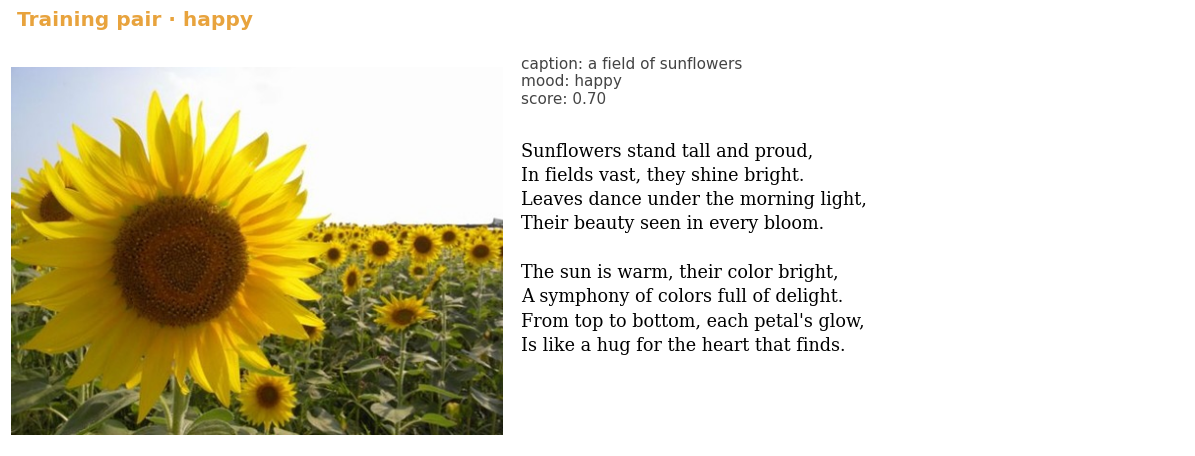

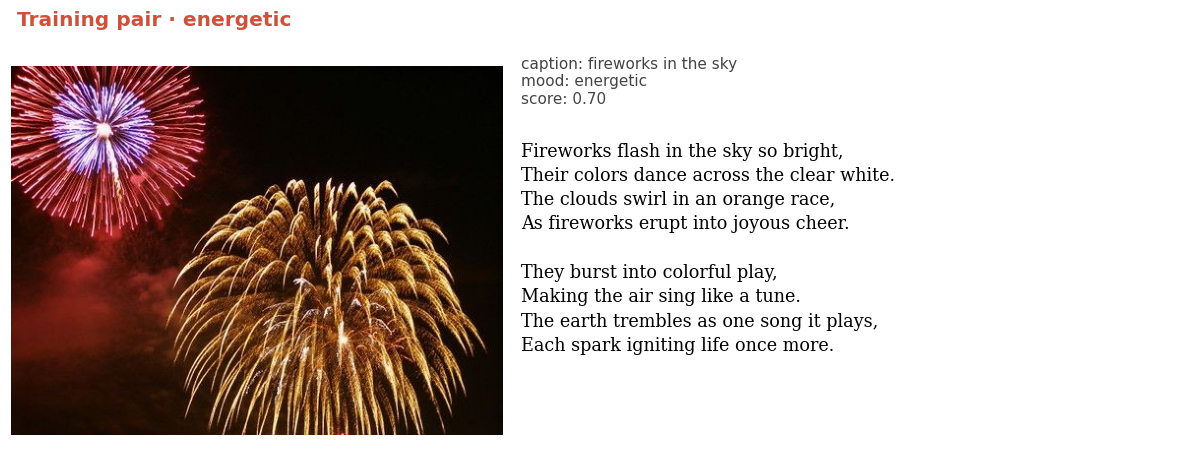

In [18]:
def show_pair(row, title=None, extra=None):
    # image on the left, caption / mood / poem on the right
    fig, (a_img, a_txt) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.35]})
    img = Image.open(DATA_DIR / row["image"]).convert("RGB")
    img.thumbnail((500, 500))
    a_img.imshow(img); a_img.axis("off")
    a_txt.axis("off")
    head = f"caption: {row['caption']}\nmood: {row['mood']}" + (f"\n{extra}" if extra else "")
    a_txt.text(0, 1, head, va="top", fontsize=10, color="#444", wrap=True)
    a_txt.text(0, 0.78, row["poem"], va="top", fontsize=11.5, family="serif", linespacing=1.45)
    fig.suptitle(title or "", fontweight="bold", color=MOOD_COLORS.get(row["mood"], "#222"), x=0.02, ha="left")
    plt.tight_layout(); plt.show()


if not missing(POEMS_DIR / "train.jsonl"):
    train_rows = load_jsonl(POEMS_DIR / "train.jsonl")
    shown_moods = []
    for r in sorted(train_rows, key=lambda r: -r.get("score", 0)):     # best-scoring, 3 different moods
        if r["mood"] not in shown_moods:
            shown_moods.append(r["mood"])
            show_pair(r, title=f"Training pair · {r['mood']}", extra=f"score: {r.get('score', float('nan')):.2f}")
        if len(shown_moods) == 3:
            break

## 6 · Fine-tuning the poem model (supervised learning with LoRA)

**Supervised learning, again** — just with text:
* input **x** = `"Write a short 8-line poem about: <caption>. Mood: <mood>. Use vivid imagery…"`
* target **y** = the kept poem from section 5
* **loss** = **cross-entropy** of predicting the next token of *y*.

**Loss masking:** the prompt tokens get label `-100` → PyTorch ignores them. The model is only graded on
writing the *poem*, not on repeating the question.

**LoRA (Low-Rank Adaptation):** the 494 M pretrained weights stay **frozen**. For each big weight matrix
$W \in \mathbb{R}^{d\times k}$ (attention q/k/v/o and MLP layers) I learn a small update:

$$W' = W + \frac{\alpha}{r}\,B A, \qquad B \in \mathbb{R}^{d\times r},\; A \in \mathbb{R}^{r\times k},\; r = 16 \ll d$$

So instead of $d\cdot k$ numbers per matrix I train only $r\,(d+k)$. $B$ starts at 0, so training starts exactly
at the base model. Optimiser: **AdamW**, lr 2e-4, cosine schedule with warm-up, batch 8, 3 epochs,
gradient clipping 1.0. I watch the **validation loss** to check for **overfitting**.

In [19]:
if RETRAIN_POET:   # heavy: LoRA training on the train pairs, val loss every 10 steps
    from src import train_poet
    train_poet.main()
    inline_again()
else:
    print("RETRAIN_POET=False -> using saved models/poet_lora/ + reports/poet_loss.csv")

# LoRA arithmetic for ONE matrix: q_proj in Qwen2.5-0.5B is 896 x 896
d = k = 896; r = 16
print(f"\none 896x896 matrix: full fine-tune {d * k:,} numbers   vs   LoRA r=16: {r * (d + k):,} "
      f"({r * (d + k) / (d * k):.1%})")

if not missing(LORA_DIR / "train_info.json"):
    info = json.load(open(LORA_DIR / "train_info.json"))
    display(pd.Series(info, name="value").to_frame())
    pct = info["trainable_params"] / info["total_params"]
    print(f"\nTrainable: {info['trainable_params']:,} of {info['total_params']:,} parameters = {pct:.2%}  "
          f"→ trained in {info['train_seconds'] / 60:.1f} min on {info['device']}")

RETRAIN_POET=False -> using saved models/poet_lora/ + reports/poet_loss.csv

one 896x896 matrix: full fine-tune 802,816 numbers   vs   LoRA r=16: 28,672 (3.6%)


,value
base,Qwen/Qwen2.5-0.5B-Instruct
train_pairs,270
val_pairs,19
epochs,3
batch,8
micro_batch,4
grad_accum,2
lr,0.0002
lora_r,16
trainable_params,8798208



Trainable: 8,798,208 of 502,830,976 parameters = 1.75%  → trained in 5.8 min on mps


In [20]:
# Loss masking, shown on a real training example (needs only the tokenizer, ~1 s)
if not missing(POEMS_DIR / "train.jsonl"):
    from transformers import AutoTokenizer
    from src.poem import BASE_NAME
    from src.train_poet import encode
    tok = AutoTokenizer.from_pretrained(BASE_NAME)
    ex = encode(tok, load_jsonl(POEMS_DIR / "train.jsonl")[0])
    n_masked = sum(l == -100 for l in ex["labels"])
    n_total = len(ex["labels"])
    print(f"tokens in example: {n_total}   prompt (label -100, ignored): {n_masked}   "
          f"poem (trained on): {n_total - n_masked}")
    first = n_masked
    print("\nlast prompt tokens :", repr(tok.decode(ex["input_ids"][first - 6:first])))
    print("first target tokens:", repr(tok.decode(ex["input_ids"][first:first + 12])))

tokens in example: 133   prompt (label -100, ignored): 67   poem (trained on): 66

last prompt tokens : '.<|im_end|>\n<|im_start|>assistant\n'
first target tokens: 'He wears his sunglasses high up,\nA smile that lights up'


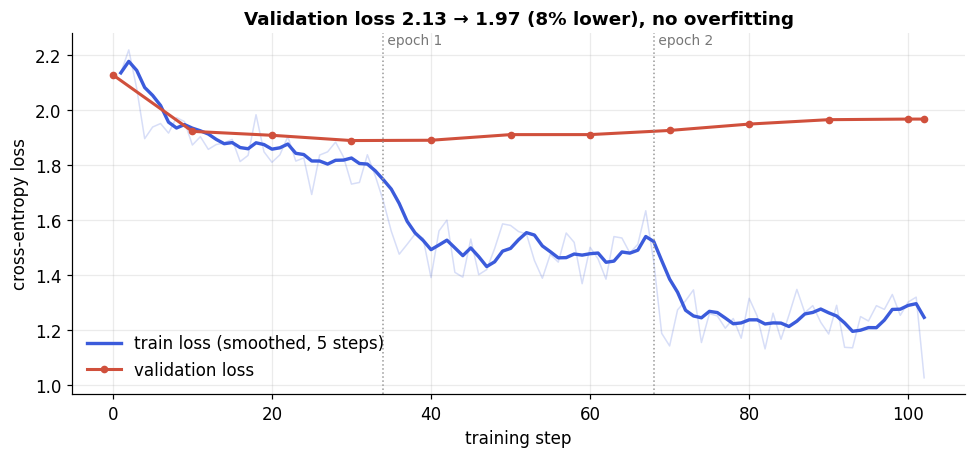

In [21]:
if not missing(REPORTS_DIR / "poet_loss.csv"):
    loss = pd.read_csv(REPORTS_DIR / "poet_loss.csv")
    tr = loss.dropna(subset=["train_loss"])
    va = loss.dropna(subset=["val_loss"])
    fig, ax = plt.subplots(figsize=(9, 4.3))
    ax.plot(tr["step"], tr["train_loss"], color=FT_C, alpha=0.2, lw=1)
    ax.plot(tr["step"], tr["train_loss"].rolling(5, min_periods=1).mean(), color=FT_C, lw=2.2,
            label="train loss (smoothed, 5 steps)")
    ax.plot(va["step"], va["val_loss"], "o-", color="#d0503c", lw=2, ms=4, label="validation loss")
    steps_per_epoch = tr["step"].max() / max(tr["epoch"].max(), 1)
    for e in range(1, int(round(tr["epoch"].max()))):
        ax.axvline(e * steps_per_epoch, color="#999", ls=":", lw=1)
        ax.text(e * steps_per_epoch, ax.get_ylim()[1], f" epoch {e}", va="top", fontsize=9, color="#777")
    ax.set_xlabel("training step"); ax.set_ylabel("cross-entropy loss")
    v0, v1, vmin = va["val_loss"].iloc[0], va["val_loss"].iloc[-1], va["val_loss"].min()
    verdict = "no overfitting" if v1 <= vmin * 1.05 else "val loss rises at the end → slight overfitting"
    ax.set_title(f"Validation loss {v0:.2f} → {v1:.2f} ({(v0 - v1) / v0:.0%} lower), {verdict}")
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

## 7 · Evaluation: base vs fine-tuned on **unseen test images**

Test images were never used for training or for choosing anything. For every test image, **both** models get the
**same short prompt** and write 3 poems each (sampling, temperature 0.9). The **raw output** is scored — no
trimming to 8 lines — so formatting mistakes count.

| Metric | Meaning (0–1, higher = better) |
|---|---|
| lines | is it exactly 8 lines? |
| rhyme | share of line pairs that rhyme (CMU pronouncing dictionary) |
| keyword | share of caption words used in the poem → *fits the picture* |
| mood | uses words that fit the mood |
| CLIP | cosine similarity between the image and the poem text (independent of my scorer) |

> Caveat: lines / rhyme / keyword / mood are the *same* scorer I used to filter the training data, so the
> fine-tuned model is partly trained "to the test". **CLIP** is an independent check.

In [22]:
if REEVAL_POET:   # heavy: 3 poems per test image per model + CLIP score
    from src import eval_poet
    eval_poet.main()
    inline_again()
else:
    print("REEVAL_POET=False -> using saved reports/poet_eval.csv")

HAVE_EVAL = not missing(REPORTS_DIR / "poet_eval.csv")
if HAVE_EVAL:
    ev = pd.read_csv(REPORTS_DIR / "poet_eval.csv")
    # NOTE: in poet_eval.csv the column "mood" holds the mood SCORE (score_poem overwrites the label);
    # the true mood label is the folder name in the image path, e.g. "calm/xyz.jpg".
    ev["mood_label"] = ev["image"].str.split("/").str[0]
    print(f"{len(ev)} poems = {ev.image.nunique()} test images × {ev.groupby(['model', 'image']).size().iloc[0]} "
          f"poems × {ev.model.nunique()} models")

REEVAL_POET=False -> using saved reports/poet_eval.csv
156 poems = 26 test images × 3 poems × 2 models


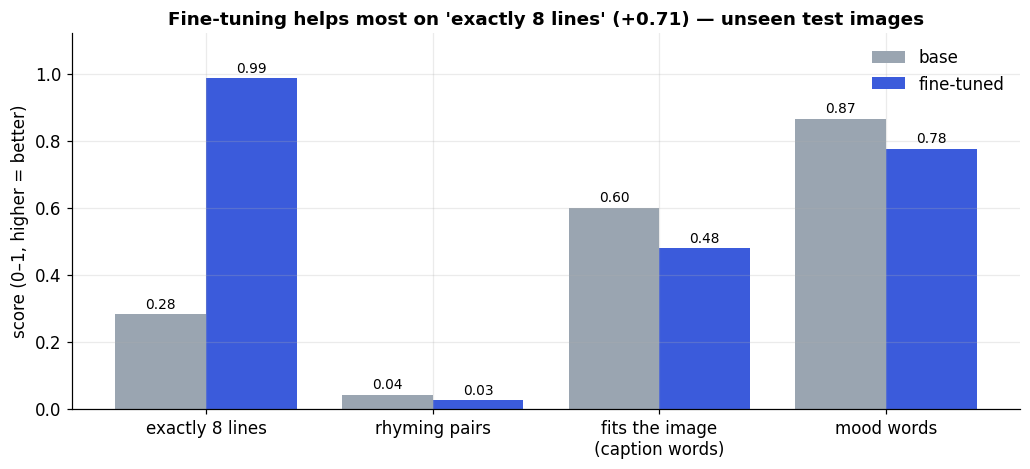

In [23]:
if HAVE_EVAL:
    metrics = {"lines": "exactly 8 lines", "rhyme": "rhyming pairs",
               "keyword": "fits the image\n(caption words)", "mood": "mood words"}
    g = ev.groupby("model")[list(metrics)].mean().reindex(["base", "fine-tuned"])
    x = np.arange(len(metrics))
    fig, ax = plt.subplots(figsize=(9.5, 4.4))
    for off, name, color in ((-0.2, "base", BASE_C), (0.2, "fine-tuned", FT_C)):
        b = ax.bar(x + off, g.loc[name].values, 0.4, color=color, label=name)
        ax.bar_label(b, fmt="%.2f", fontsize=9, padding=2)
    ax.set_xticks(x, metrics.values()); ax.set_ylim(0, 1.12)
    ax.set_ylabel("score (0–1, higher = better)")
    gain = (g.loc["fine-tuned"] - g.loc["base"])
    ax.set_title(f"Fine-tuning helps most on '{metrics[gain.idxmax()].splitlines()[0]}' "
                 f"(+{gain.max():.2f}) — unseen test images")
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

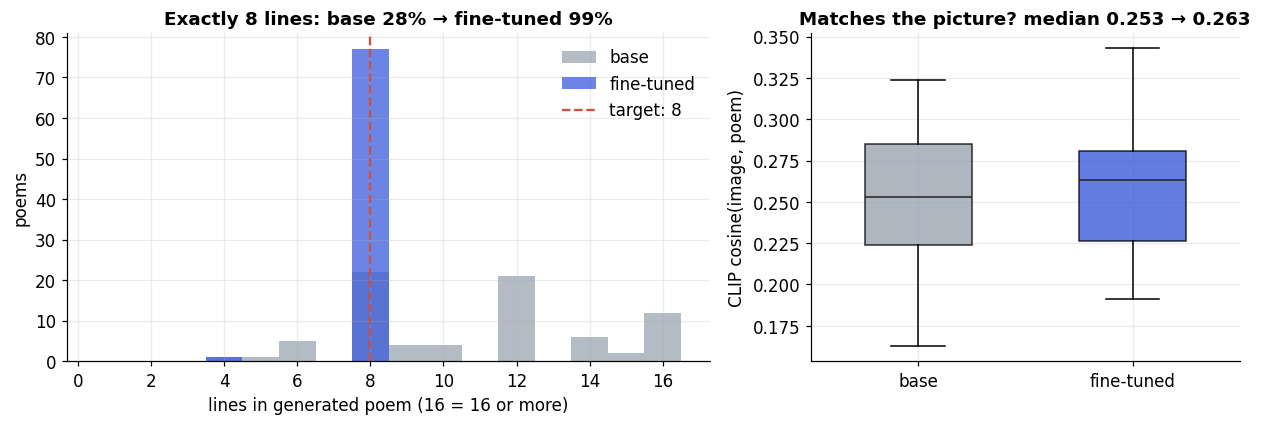

In [24]:
if HAVE_EVAL:
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4), gridspec_kw={"width_ratios": [1.5, 1]})
    bins = np.arange(1, 18) - 0.5
    for name, color in (("base", BASE_C), ("fine-tuned", FT_C)):
        a1.hist(ev[ev.model == name]["n_lines"].clip(upper=16), bins=bins, alpha=0.75, color=color, label=name)
    a1.axvline(8, color="#d0503c", ls="--", lw=1.5, label="target: 8")
    a1.set_xlabel("lines in generated poem (16 = 16 or more)"); a1.set_ylabel("poems")
    share = ev.groupby("model")["lines"].mean()
    a1.set_title(f"Exactly 8 lines: base {share.get('base', 0):.0%} → fine-tuned {share.get('fine-tuned', 0):.0%}")
    a1.legend(frameon=False)

    data = [ev[ev.model == m]["clip"] for m in ("base", "fine-tuned")]
    bp = a2.boxplot(data, tick_labels=["base", "fine-tuned"], patch_artist=True, widths=0.5,
                    medianprops=dict(color="#222"))
    for patch, color in zip(bp["boxes"], (BASE_C, FT_C)):
        patch.set_facecolor(color); patch.set_alpha(0.8)
    med = [d.median() for d in data]
    a2.set_ylabel("CLIP cosine(image, poem)")
    a2.set_title(f"Matches the picture? median {med[0]:.3f} → {med[1]:.3f}")
    plt.tight_layout(); plt.show()

In [25]:
if HAVE_EVAL:
    cols = ["lines", "rhyme", "keyword", "mood", "clip", "total"]
    summary = ev.groupby("model")[cols].mean().reindex(["base", "fine-tuned"])
    summary.loc["change"] = summary.loc["fine-tuned"] - summary.loc["base"]
    display(summary.round(3).style.format("{:.3f}").set_caption("Mean scores on test images (higher = better)"))
    print("\nper true mood (total score):")
    display(ev.pivot_table(index="mood_label", columns="model", values="total", aggfunc="mean")
              .reindex(MOODS).round(3))

,lines,rhyme,keyword,mood,clip,total
model,,,,,,
base,0.282,0.042,0.599,0.865,0.251,0.409
fine-tuned,0.987,0.026,0.478,0.776,0.255,0.371
change,0.705,-0.016,-0.121,-0.090,0.004,-0.038



per true mood (total score):


model,base,fine-tuned
mood_label,,
happy,0.523,0.396
sad,0.321,0.360
calm,0.475,0.374
energetic,0.341,0.359


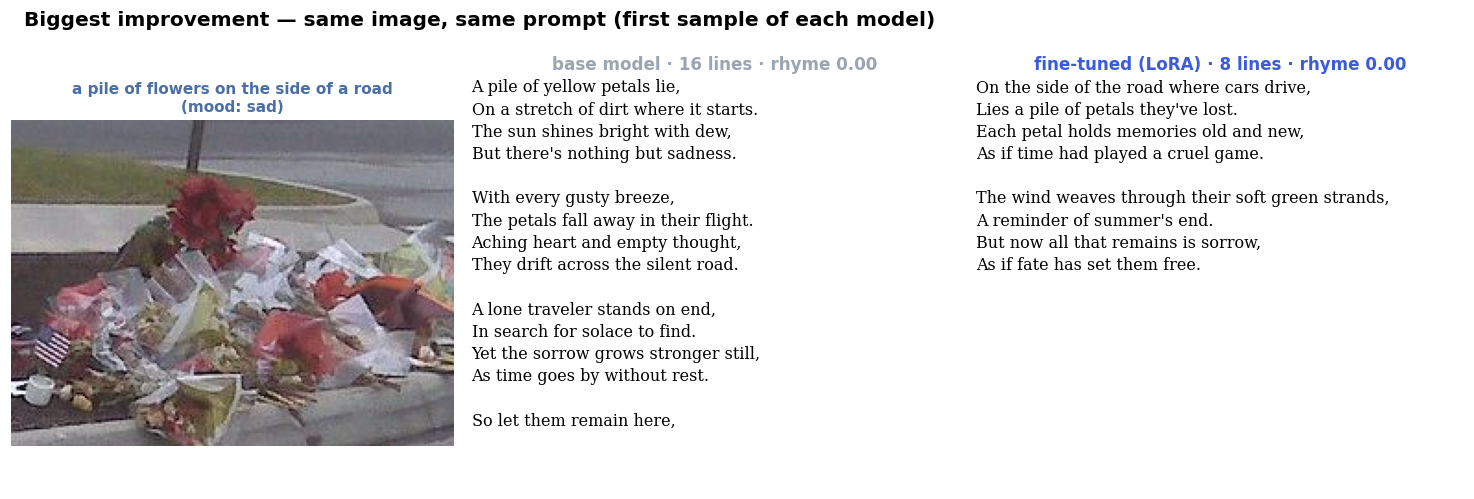

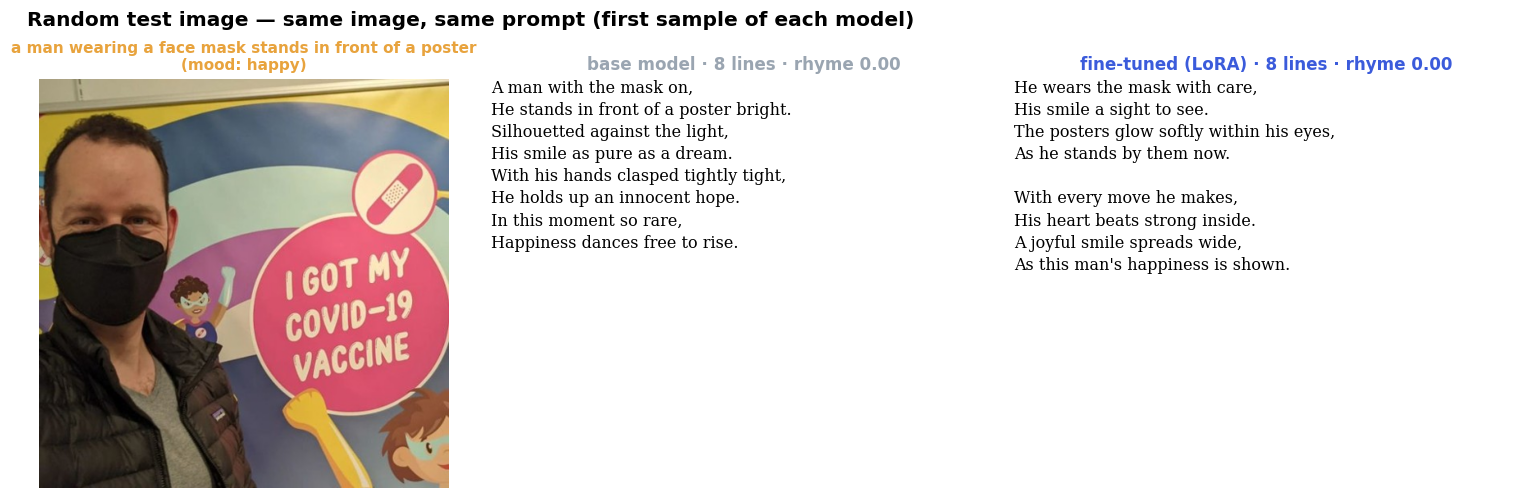

In [26]:
def side_by_side(image, caption, mood, base_poem, ft_poem, title):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
    img = Image.open(DATA_DIR / image).convert("RGB"); img.thumbnail((500, 500))
    axes[0].imshow(img); axes[0].axis("off")
    axes[0].set_title(f"{caption}\n(mood: {mood})", fontsize=10, color=MOOD_COLORS.get(mood, "#222"))
    for ax, poem, name, color in ((axes[1], base_poem, "base model", BASE_C),
                                  (axes[2], ft_poem, "fine-tuned (LoRA)", FT_C)):
        ax.axis("off")
        s = score_poem(poem, caption, mood)
        ax.set_title(f"{name} · {s['n_lines']} lines · rhyme {s['rhyme']:.2f}", color=color, fontsize=11)
        shown = "\n".join(poem.splitlines()[:16])
        ax.text(0, 1, shown, va="top", fontsize=10.5, family="serif", linespacing=1.4, wrap=True)
    fig.suptitle(title, fontweight="bold", x=0.02, ha="left")
    plt.tight_layout(); plt.show()


if HAVE_EVAL:
    per_img = ev.pivot_table(index="image", columns="model", values="total", aggfunc="mean")
    per_img["gain"] = per_img["fine-tuned"] - per_img["base"]
    picks = [(per_img["gain"].idxmax(), "Biggest improvement"),
             (per_img.drop(per_img["gain"].idxmax()).sample(1, random_state=3).index[0], "Random test image")]
    for img_path, why in picks:
        sub = ev[ev.image == img_path]
        b = sub[sub.model == "base"].iloc[0]          # first sample of each model (not cherry-picked)
        f = sub[sub.model == "fine-tuned"].iloc[0]
        side_by_side(img_path, b["caption"], b["mood_label"], b["poem"], f["poem"],
                     f"{why} — same image, same prompt (first sample of each model)")

## 8 · Full pipeline, live

One test image through the whole system, exactly like the app: **BLIP caption → CLIP + my classifier → my
fine-tuned poet**. Loading the models happens once (like when the server starts); then I time each step.

In [27]:
from src.caption import caption_image, load_blip
from src.mood import load_mood_model, predict_mood
from src.poem import write_poem, load_poet, poet_name
from src.features import load_clip

with timer("load all models (once, at server start)"):
    load_blip(); load_clip(); load_poet()
    pca_m, clf_m, clf_name = load_mood_model()

if (POEMS_DIR / "test.jsonl").exists():
    demo_rel = load_jsonl(POEMS_DIR / "test.jsonl")[0]["image"]        # an unseen test image
    demo_path = DATA_DIR / demo_rel
else:
    demo_path = Path(np.random.default_rng(1).choice([str(p) for p in paths]))
print("demo image:", demo_path.relative_to(ROOT))
demo_img = Image.open(demo_path).convert("RGB")

t = {}
t0 = time.perf_counter(); caption = caption_image(demo_img);                    t["caption (BLIP)"] = time.perf_counter() - t0
t0 = time.perf_counter(); mood, conf, probs = predict_mood(demo_img, pca_m, clf_m); t[f"mood (CLIP + {clf_name})"] = time.perf_counter() - t0
t0 = time.perf_counter(); poem = write_poem(caption, mood);                     t[f"poem ({poet_name()})"] = time.perf_counter() - t0

for k_, v_ in t.items():
    print(f"  {k_:32s} {v_:5.2f}s")
print(f"  {'TOTAL':32s} {sum(t.values()):5.2f}s")

[time] load BLIP: 0.10s
[time] load CLIP: 0.13s


Poem model: fine-tuned (LoRA adapter from models/poet_lora)
[time] load poem model: 0.65s
[time] load all models (once, at server start): 0.88s
demo image: data/happy/01c99056-c594-4fc9-9e94-219906d773cb.jpg


  caption (BLIP)                    1.51s
  mood (CLIP + KNN)                 0.12s
  poem (fine-tuned poet (LoRA))     2.71s
  TOTAL                             4.34s


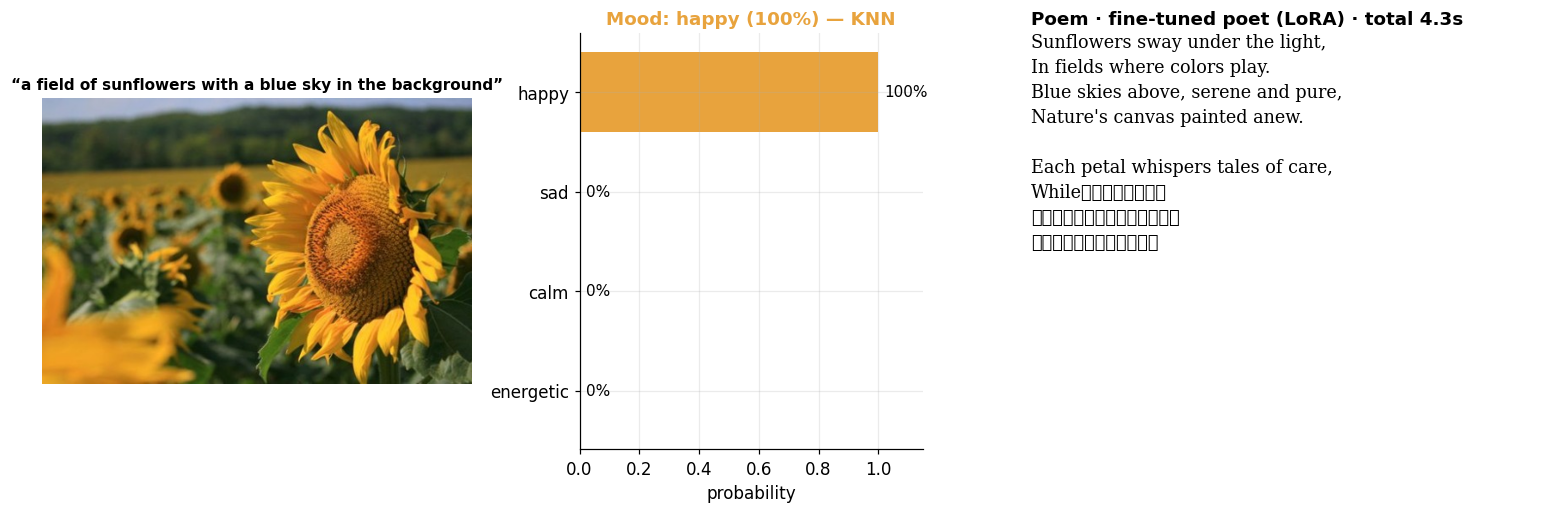

In [28]:
fig = plt.figure(figsize=(14, 4.8))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 0.8, 1.2])
a_img, a_prob, a_poem = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])

shown = demo_img.copy(); shown.thumbnail((500, 500))
a_img.imshow(shown); a_img.axis("off")
a_img.set_title(f"“{caption}”", fontsize=10)

ms = [m for m in MOODS if m in probs]
a_prob.barh(ms, [probs[m] for m in ms], color=[MOOD_COLORS[m] for m in ms])
for i_, m in enumerate(ms):
    a_prob.text(probs[m] + 0.02, i_, f"{probs[m]:.0%}", va="center", fontsize=10)
a_prob.set_xlim(0, 1.15); a_prob.invert_yaxis(); a_prob.set_xlabel("probability")
a_prob.set_title(f"Mood: {mood} ({conf:.0%}) — {clf_name}", color=MOOD_COLORS[mood])

a_poem.axis("off")
a_poem.text(0, 1, poem, va="top", fontsize=11.5, family="serif", linespacing=1.5)
a_poem.set_title(f"Poem · {poet_name()} · total {sum(t.values()):.1f}s", loc="left")
plt.tight_layout(); plt.show()

## 9 · Deployment

**Saving models**
* mood model: `joblib.dump` → `models/pca.joblib` (StandardScaler + PCA) and `models/mood_model.joblib`
  (the best classifier, refit on all images). `src/mood.py` loads them with `joblib.load` and gives a clear error
  if they are missing.
* poem model: only the **LoRA adapter** is saved (`model.save_pretrained` → `models/poet_lora/`, a few MB instead
  of ~2 GB). At start-up `src/poem.py` loads the base model, adds the adapter and **merges** it
  (`merge_and_unload`) → same speed as the base model. If no adapter exists, it falls back to the base model.

**Serving** — `python app.py` starts *one* server (FastAPI + uvicorn) on port 7860:

| URL | What |
|---|---|
| `/` | static website (`site/`) with a chat: drop an image → caption, mood, poem, timing |
| `/gradio` | classic Gradio UI (upload → caption, mood bars, poem, “Regenerate poem”) |
| `POST /api/poem` | JSON API: `curl -F image=@photo.jpg http://127.0.0.1:7860/api/poem` |
| `POST /api/regenerate` | new poem for the same caption + mood |

All models load **once** at start-up; a lock handles one request at a time so CPU timings stay honest.

In [29]:
def size(p):
    p = Path(p)
    b = sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) if p.is_dir() else p.stat().st_size
    return f"{b / 1e6:,.2f} MB"

files = [FEATURES_FILE, PCA_FILE, MODEL_FILE, LORA_DIR]
display(pd.DataFrame([{"artifact": str(Path(p).relative_to(ROOT)),
                       "size": size(p) if Path(p).exists() else "missing"} for p in files]))
print(f"\nWhole notebook ran in {time.perf_counter() - NOTEBOOK_START:.0f}s")

,artifact,size
0,models/features.npz,0.52 MB
1,models/pca.joblib,0.25 MB
2,models/mood_model.joblib,0.12 MB
3,models/poet_lora,35.24 MB



Whole notebook ran in 13s


## 10 · Syllabus map

| Syllabus topic | Where in the project | Section |
|---|---|---|
| Data collection & labelling | `src/build_dataset.py`, hand cleaning | 1 |
| **Feature extraction** (pretrained CNN/ViT) | `src/features.py` (frozen CLIP) | 2 |
| **Preprocessing** (normalisation, scaling) | L2-norm + `StandardScaler` in the Pipeline | 2, 3 |
| **PCA** / dimensionality reduction | `src/train_mood.py` (90 % variance) | 2 |
| **Classification**: Logistic Regression, KNN, Decision Tree | `src/train_mood.py` | 3 |
| **Ensembles**: Random Forest | `src/train_mood.py` | 3 |
| **Neural networks**: MLP | `src/train_mood.py` | 3 |
| **Evaluation**: train/test split, **k-fold CV**, accuracy, precision/recall/F1, **confusion matrix** | `src/evaluate.py` | 3, 7 |
| **Clustering**: K-Means, elbow, silhouette, ARI | `src/evaluate.py`, this notebook | 4 |
| **Visualisation**: PCA 2-D, **t-SNE** | this notebook | 4 |
| Dataset creation, **rejection sampling** | `src/poem_data.py`, `src/poem_metrics.py` | 5 |
| **Transfer learning / fine-tuning**, **LoRA**, cross-entropy, AdamW, overfitting check | `src/train_poet.py` | 6 |
| Before/after evaluation on held-out data | `src/eval_poet.py` | 7 |
| **Model saving & deployment** | `joblib`, `save_pretrained`, `app.py` | 8, 9 |

## Viva Q & A

1. **Is the poem model trained from scratch?**
   No. It is **Qwen2.5-0.5B-Instruct**, pretrained by Alibaba on huge text data. I **fine-tuned** it with **LoRA**
   on my own image → poem dataset. Training a language model from scratch needs billions of tokens and GPU
   clusters; on a laptop the right choice is **transfer learning**: keep the knowledge, train ~1–2 % new weights
   for my task. It trained in minutes and the adapter is only a few MB.
2. **What did you train from scratch?** The mood classifier (scaler + PCA + 5 compared models). BLIP and CLIP are
   frozen pretrained models.
3. **Why freeze CLIP instead of training a CNN?** Only 251 images — a CNN from scratch would overfit badly.
   CLIP already knows visual concepts, so a small classifier on its features works well (~85 % accuracy).
4. **Why PCA before the classifier?** 512 features vs ~200 training images → overfitting risk. PCA keeps 90 % of the
   variance with far fewer features and removes noise / correlated features.
5. **Why is everything inside a Pipeline?** So the scaler and PCA are fit only on the training folds during CV
   → no **data leakage** from the validation fold.
6. **Why choose the model by CV and not by test accuracy?** Choosing by test would make the test score optimistic.
   CV picks; the test set is a single honest final check.
7. **Why did K-Means not find the moods?** Mood is a human concept; CLIP vectors cluster more by content
   (people, water, city…). Silhouette and ARI are low → supervised labels are needed.
8. **Where do the training poems come from?** The base model with a strict teacher prompt writes 8 candidates per
   image; my scorer keeps the best (**rejection sampling / prompt distillation**). Not human-written — I say that
   openly.
9. **What is LoRA?** Freeze W, learn W + (α/r)·B·A with rank r = 16. Far fewer trainable parameters, less memory,
   less overfitting, and the base model stays untouched.
10. **How do you know fine-tuning helped and is not just overfitting?** Validation loss goes down during training,
    and on **unseen test images** the fine-tuned model scores higher on lines / rhyme / keyword / mood; CLIP
    similarity is an independent check that the poems still match the picture.